# ---
## **1. Definition**
# ---

# ---
### 1.1. Project Overview
#### **Background** --> Tomatoes play very important role in the agricultural sector. They are very widespread due to their demand. Unfortunately tomatoes are susceptible to diseases. (Singh, Singh and Kumar, 2017) state that tomatoes can be plagued by upwards of 200 diseases. These diseases can vary in severity but almost always they lead to significant financial and production losses.

#### **Problem Domain** --> Manual ways to detect which plants have been affected can be tedious and costly process additionally it can be very unreliable. However, nowadays there very robust computer vision models that can automate this processes can significantly reduce the need for the employees to manually survey the plantations.

#### **Dataset** --> ""Tomato Leaf Disease Detection - YOLOv8 Dataset"" from Kaggle will be used in this project. Can be found at the link below.
[https://www.kaggle.com/datasets/vasantharank/tomato-leaf-disease-detection-yolov8-dataset/data](https://www.kaggle.com/datasets/vasantharank/tomato-leaf-disease-detection-yolov8-dataset/data)

# ---

# ---
### 1.2. Problem Statement
#### **There is a need for automated and robust models that can identify and classify diseases from images of leaves in a reliable and timely manner.Current methods of classification can be inefficient as they are costly, slow.These inefficiencies can allow diseases to spread and affect the whole crop. This consequently can cause shortages and affect financial ability of the sector.**

# ---

# ---
### 1.3. Solution Statement
#### **Goal** --> Develop, tune and evaluate latest YOLOv8 pre-trained model for classification of 9 classes of diseases with 1 class of healthy leaves.
#### **Solution** --> Fine Tuned YOLOv8 model trained on the Tomato dataset. YOLOv8 is exceptional in real-time object detection. It is highly balanced in terms of accuracy and speed. There multiple types of model starting from nano all the way to the x-large this provides scalability. Frameworks are very to use and are optimized to work on multiple platforms. The model is expected to toke standard image as "jpg" files and provide output in the for detected object as bounding boxes along with class the image belongs to.
#### **Future Deployment Options** --> After training the model it is possible to deploy the model on mobile devices for people to use on the fields to accurately identify diseased leaves.

# ---

# ---
### 1.4. Evaluation Metrics
#### **Metrics Chosen:** --> Precision, Recall, F1-Score, Mean Average Precision(mAP) and Time.
#### **Justifications**
#### Precision --> By monitoring precision it is possible to minimize false alarms which can accumulate additional labor costs.
#### Recall --> By monitoring recall it is possible to minimize missed detections which can lower the productivity of the model.
#### F1-Score --> By monitoring f1-score it is possible to balance precision and recall to get meaningful evaluation.
#### mAP --> Is a standard object detection metric includes localization and classification accuracy.
#### Time --> Object detection models usually use FPS as a metric to evaluate time. Lowest threshold for this metric will be 15 FPS.
# ---

# ---
## **2. Analysis**
# ---

# ---
### 2.1. Data Exploration
#### **Dataset Description** --> The dataset is a collection of images of tomato leaves consisting of 10 classes the data was collected from kaggle. Data originally is resized however, not augmented. Dataset originally is created with YOLOv8 model in mind and has the structure that fits the model perfectly.
#### **Dataset Link** --> [https://www.kaggle.com/datasets/vasantharank/tomato-leaf-disease-detection-yolov8-dataset/data](https://www.kaggle.com/datasets/vasantharank/tomato-leaf-disease-detection-yolov8-dataset/data)
#### **Dataset Size** --> Total 10853 images.
#### **Data Split** --> 72% Train (7842) || 18% Validation (1960) || 10% Test (1051)
#### **Data Classes** -->
- #### Tomato Bacterial Spot
- #### Tomato Early Blight
- #### Tomato Late Blight
- #### Tomato Leaf Mold
- #### Tomato Septoria Leaf Spot
- #### Tomato Spider Mites (Two-Spotted Spider Mite)
- #### Tomato Target Spot
- #### Tomato Yellow Leaf Curl Virus
- #### Tomato Healthy
- #### Tomato Mosaic Virus
#### **Data Image Size** --> 640x640 pixels in JPG format.
#### **Data Annotation** --> YOLOv8 format
# ---

In [1]:
import os
import yaml
import glob
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from ultralytics import YOLO
import time
import platform
import subprocess

In [3]:
DATA_DIR = 'data'

In [4]:
TRAINING_IMG_DIR = os.path.join(DATA_DIR, "train/images")
TRAINING_LBL_DIR = os.path.join(DATA_DIR, "train/labels")
VALIDATION_IMG_DIR = os.path.join(DATA_DIR, "valid/images")
VALIDATION_LBL_DIR = os.path.join(DATA_DIR, "valid/labels")
TEST_IMG_DIR = os.path.join(DATA_DIR, "test/images")
TEST_LBL_DIR = os.path.join(DATA_DIR, "test/labels")
YAML_PATH = os.path.join(DATA_DIR, "data.yaml")

In [5]:
yaml_content = {
    "train": os.path.abspath(TRAINING_IMG_DIR),
    "val": os.path.abspath(VALIDATION_IMG_DIR),
    "test": os.path.abspath(TEST_IMG_DIR),
    "nc": 10,
    "names": [
        "Tomato Bacterial Spot",
        "Tomato Early Blight",
        "Tomato Late Blight",
        "Tomato Leaf Mold",
        "Tomato Septoria Leaf Spot",
        "Tomato Spider Mites (Two-Spotted Spider Mite)",
        "Tomato Target Spot",
        "Tomato Yellow Leaf Curl Virus",
        "Tomato Healthy",
        "Tomato Mosaic Virus",
    ],
}

In [6]:
try:
  with open(YAML_PATH, 'w') as f:
    yaml.dump(yaml_content, f, default_flow_style=False)
    print(f'Yaml populated at {YAML_PATH}')
  with open(YAML_PATH, 'r') as f:
    print(f.read())
except Exception as e:
  print("Error writing file:", e)

Yaml populated at data\data.yaml
names:
- Tomato Bacterial Spot
- Tomato Early Blight
- Tomato Late Blight
- Tomato Leaf Mold
- Tomato Septoria Leaf Spot
- Tomato Spider Mites (Two-Spotted Spider Mite)
- Tomato Target Spot
- Tomato Yellow Leaf Curl Virus
- Tomato Healthy
- Tomato Mosaic Virus
nc: 10
test: c:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\test\images
train: c:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\train\images
val: c:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\valid\images



In [7]:
def file_counter(dir_img, lbl_dir):
  img_count = len(glob.glob1(dir_img, "*.jpg"))
  lbl_count = len(glob.glob1(lbl_dir, "*.txt"))
  return img_count, lbl_count

In [8]:
train_img, train_lbl = file_counter(TRAINING_IMG_DIR, TRAINING_LBL_DIR)
valid_img, valid_lbl = file_counter(VALIDATION_IMG_DIR, VALIDATION_LBL_DIR)
test_img, test_lbl = file_counter(TEST_IMG_DIR, TEST_LBL_DIR)

In [9]:
print(f'Training Set containcs {train_img} images and {train_lbl} labels')
print(f'Validation Set containcs {valid_img} images and {valid_lbl} labels')
print(f'Test Set containcs {test_img} images and {test_lbl} labels')

Training Set containcs 7842 images and 7842 labels
Validation Set containcs 1960 images and 1960 labels
Test Set containcs 1051 images and 1051 labels


In [10]:
count_class = Counter()
labels = glob.glob(os.path.join(TRAINING_LBL_DIR, "*.txt"))

for i in labels:
  try:
    with open(i,"r") as f:
      for v in f:
        id_class = int(v.strip().split()[0])
        count_class[id_class] += 1
  except Exception as e:
    print("Error reading", e)

In [11]:
try:
  with open(YAML_PATH, 'r') as f:
    inf = yaml.safe_load(f)
    class_lbls = inf['names']
except Exception as e:
  print("Error reading file:", e)

In [12]:
label_data = pd.DataFrame({
	"Class" : [class_lbls[i] for i in sorted(count_class.keys())],
	"Frequency" : [count_class[i] for i in sorted(count_class.keys())],
})
print(label_data)

                                           Class  Frequency
0                          Tomato Bacterial Spot        106
1                            Tomato Early Blight        715
2                             Tomato Late Blight        105
3                               Tomato Leaf Mold       1079
4                      Tomato Septoria Leaf Spot       1074
5  Tomato Spider Mites (Two-Spotted Spider Mite)       1098
6                             Tomato Target Spot       1022
7                  Tomato Yellow Leaf Curl Virus       1063
8                                 Tomato Healthy        518
9                            Tomato Mosaic Virus        965


C:\Users\ASUS ROG\AppData\Local\Temp\ipykernel_13396\1426897838.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Class", y="Frequency", data=label_data, palette="crest")


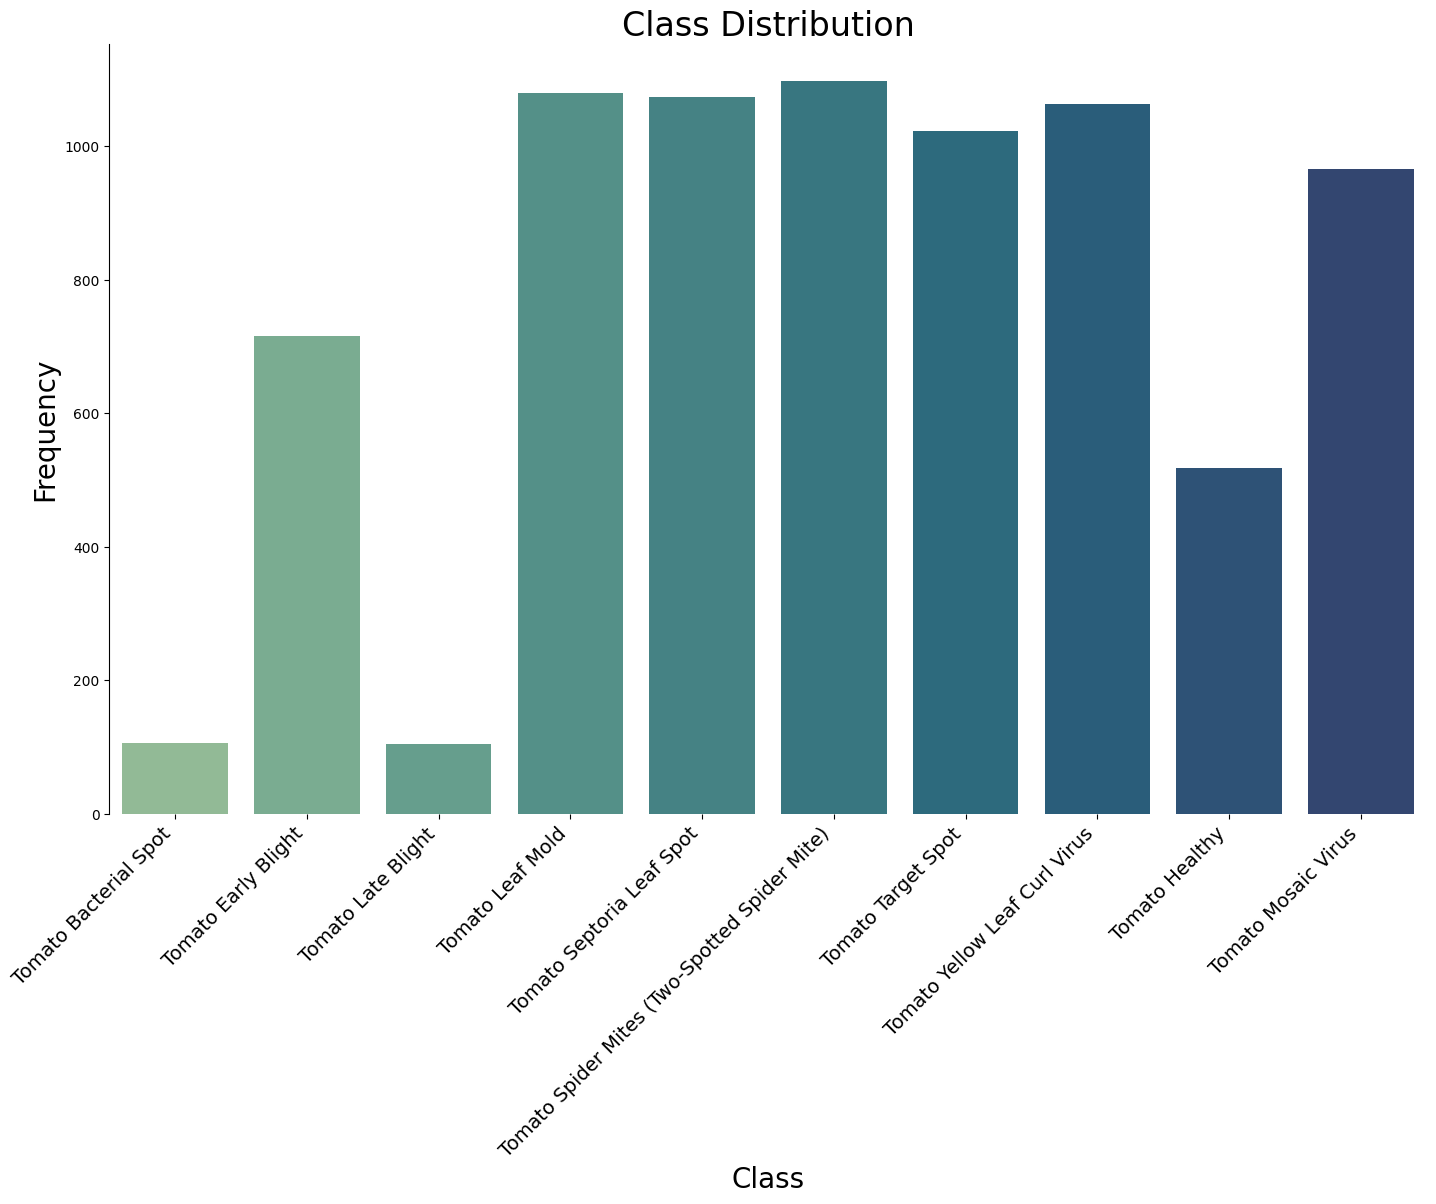

In [13]:
plt.figure(figsize=(17, 10))
sns.barplot(x="Class", y="Frequency", data=label_data, palette="crest")
plt.title("Class Distribution", fontsize=24)
plt.xlabel("Class", fontsize=20)
plt.ylabel("Frequency", fontsize=20)
sns.despine()
plt.grid(False)
plt.gca().spines['bottom'].set_visible(False)
plt.xticks(rotation=45, ha='right', fontsize=14)
plt.show()

# ---
### 2.2. Exploratory Visualization Explanation
#### Bar chart above show the class distribution in the dataset. It can be seen that some classes are under-represented such as bacterial spot and late blight. While the imbalance might affect the training results the model will still provide meaningful results as other classes are approximately balanced.
# ---

# ---
### 2.3. Algorithms and Techniques
#### Main algorithm that will handle the training is YOLOv8 pre trained object detection model. This model is very recent and is very efficient in real-time object detection as it balances both accuracy and speed so there nearly no trade-offs. Due to the model architecture the image is processed at once and provides bounding boxes for detected objects. Additional data augmentation techniques are present in training library and will be used to reduce overfitting and enable the model to generalize better.
# ---

# ---
### 2.4. Benchmarking
#### In order to compare our trained model to the base model YOLOv5 will be used as a benchmark. YOLOv5 is a predecessor to the YOLOv8 and was used widely as well. Training YOLOv5 on the tomato dataset while providing same hyperparameters will provide a good baseline model for comparison and enable us to get better understanding on improvements and shortcomings.
# ---

# ---
## **3. Methodology**
# ---

# ---
### 3.1. Preprocessing
#### Dataset originally had the images at a consistent size of (640x640 pixels) the format and structure was already applicable for YOLO models. So no extra preprocessing steps are needed. However, ultralytics library automatically applies certain augmentations pre-training such as horizontal flipping, mosaic, combining images, color adjustments. These can help the model to learn better.
# ---

# ---
### 3.2. Implementation
#### The code is implemented with python 3.10 in Jupyter notebook and a clean environment through conda. Ultralytics library was used for training and evaluating both YOLOv5 and YOLOv5 models. The training data was passed through the data.yaml file created earlier. Data.yaml specifies paths for the splits. Hyperparameters were set at --. The training was done with a GPU locally (NVIDIA GeForce RTX 3060). Progress of the model was monitored via the console and logs.
# ---

In [14]:
print(f'Python version --> {platform.python_version()}')
print(f'PyTorch version --> {torch.__version__}')
if torch.cuda.is_available():
  print(f'GPU Available --> {torch.cuda.get_device_name(0)}')

Python version --> 3.10.16
PyTorch version --> 2.5.1+cu121
GPU Available --> NVIDIA GeForce RTX 3060 Laptop GPU


In [15]:
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print(f"Using now --> {'GPU' if isinstance(DEVICE, int) else 'CPU'}")

Using now --> GPU


In [16]:
PROJECT_DIRECTORY = 'model_artifacts'
os.makedirs(PROJECT_DIRECTORY, exist_ok=True)

In [17]:
YOLOv8_EPOCHS = 15
YOLOv8_BATCH_SIZE = 8
YOLOv8_MODEL_SIZE = 'yolov8s.pt'
YOLOv8_RUN_NAME = 'yolov8s_tomato_light'

In [96]:
if not os.path.exists(YAML_PATH):
  print('No YAML')
else:
  print("Using Yaml at", YAML_PATH)
  v8_model = YOLO(YOLOv8_MODEL_SIZE)
  YOLOv8_PATH = None
  
  try:
    res_v8 = v8_model.train(
      data=YAML_PATH,
      epochs = YOLOv8_EPOCHS,
      imgsz = 640,
      batch = YOLOv8_BATCH_SIZE,
      device = DEVICE,
      name = YOLOv8_RUN_NAME,
      project = PROJECT_DIRECTORY,
      exist_ok = True,
      patience = 5
		)
    YOLOv8_PATH = os.path.join(res_v8.save_dir, 'weights/best.pt')
    if os.path.exists(YOLOv8_PATH):
            print(f"training complete best model -->: {YOLOv8_PATH}")
    else:
            print("training complete no -->best.pt")
            YOLOv8_PATH = None
  except Exception as e:
    print("Training Failed", e)
    YOLOv8_PATH = None

Using Yaml at data\data.yaml
New https://pypi.org/project/ultralytics/8.3.101 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.100  Python-3.10.16 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: task=detect, mode=train, model=yolov8s.pt, data=data\data.yaml, epochs=15, time=None, patience=5, batch=8, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=model_artifacts, name=yolov8s_tomato_light, exist_ok=True, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=N

train: Scanning C:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\train\labels... 7842 images, 124 backgrounds, 0 corrupt: 100%|██████████| 7842/7842 [00:19<00:00, 403.53it/s]


train: New cache created: C:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\train\labels.cache


val: Scanning C:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\valid\labels... 1960 images, 37 backgrounds, 0 corrupt: 100%|██████████| 1960/1960 [00:05<00:00, 378.04it/s]


val: New cache created: C:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\valid\labels.cache
Plotting labels to model_artifacts\yolov8s_tomato_light\labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.000714, momentum=0.9) with parameter groups 57 weight(decay=0.0), 64 weight(decay=0.0005), 63 bias(decay=0.0)
Image sizes 640 train, 640 val
Using 8 dataloader workers
Logging results to model_artifacts\yolov8s_tomato_light
Starting training for 15 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


       1/15      1.98G     0.7934      1.718      1.391          7        640: 100%|██████████| 981/981 [02:28<00:00,  6.59it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 123/123 [00:17<00:00,  7.20it/s]


... (35 outputs left out)

                   all       1960       1924      0.859      0.927      0.919        0.8
EarlyStopping: Training stopped early as no improvement observed in last 5 epochs. Best results observed at epoch 8, best model saved as best.pt.
To update EarlyStopping(patience=5) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.



13 epochs completed in 0.630 hours.
Optimizer stripped from model_artifacts\yolov8s_tomato_light\weights\last.pt, 22.5MB
Optimizer stripped from model_artifacts\yolov8s_tomato_light\weights\best.pt, 22.5MB

Validating model_artifacts\yolov8s_tomato_light\weights\best.pt...
Ultralytics 8.3.100  Python-3.10.16 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summary (fused): 72 layers, 11,129,454 parameters, 0 gradients, 28.5 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 123/123 [00:17<00:00,  6.97it/s]


                   all       1960       1924      0.924      0.926      0.958      0.835
 Tomato Bacterial Spot        822        823      0.814      0.909      0.916      0.905
   Tomato Early Blight        854        854      0.949      0.722      0.894      0.701
Tomato Yellow Leaf Curl Virus         20         20      0.895          1      0.988      0.974
        Tomato Healthy        212        212      0.996          1      0.995      0.793
   Tomato Mosaic Virus         15         15      0.965          1      0.995      0.802
Speed: 0.3ms preprocess, 3.9ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to model_artifacts\yolov8s_tomato_light
training complete best model -->: model_artifacts\yolov8s_tomato_light\weights/best.pt


In [18]:
YOLOV5_DIR = "yolov5"

In [19]:
YOLOV5_EPOCHS = YOLOv8_EPOCHS
YOLOV5_BATCH_SIZE = YOLOv8_BATCH_SIZE 
YOLOV5_MODEL_SIZE = 'yolov5s.pt'
YOLOV5_RUN_NAME = 'yolov5s_tomato_benchmark_minimal'
YOLOV5_BEST_PATH = None

In [20]:
if not os.path.isdir(YOLOV5_DIR):
  print(f"No dir {YOLOV5_DIR}")
elif not os.path.exists(YAML_PATH):
     print(f"No data.yaml  {YAML_PATH}")
else:
    yolov5_dir_abs = os.path.abspath(YOLOV5_DIR)
    yaml_path_abs = os.path.abspath(YAML_PATH)
    project_dir_abs = os.path.abspath(PROJECT_DIRECTORY)
    cmd_train = cmd_train = f'python "{os.path.join(yolov5_dir_abs, "train.py")}" ' \
    f'--img 640 --batch {YOLOV5_BATCH_SIZE} --epochs {YOLOV5_EPOCHS} ' \
    f'--data "{yaml_path_abs}" --weights {YOLOV5_MODEL_SIZE} ' \
    f'--project "{project_dir_abs}" --name {YOLOV5_RUN_NAME} ' \
    f'--exist-ok --patience 5'

    print(f"Running YOLOv5")
    print(cmd_train)
    print("-" * 30)

Running YOLOv5
python "c:\Users\ASUS ROG\Desktop\tomato_disease_dataset\yolov5\train.py" --img 640 --batch 8 --epochs 15 --data "c:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\data.yaml" --weights yolov5s.pt --project "c:\Users\ASUS ROG\Desktop\tomato_disease_dataset\model_artifacts" --name yolov5s_tomato_benchmark_minimal --exist-ok --patience 5
------------------------------


In [21]:
subprocess.run(cmd_train, shell=True)

CompletedProcess(args='python "c:\\Users\\ASUS ROG\\Desktop\\tomato_disease_dataset\\yolov5\\train.py" --img 640 --batch 8 --epochs 15 --data "c:\\Users\\ASUS ROG\\Desktop\\tomato_disease_dataset\\data\\data.yaml" --weights yolov5s.pt --project "c:\\Users\\ASUS ROG\\Desktop\\tomato_disease_dataset\\model_artifacts" --name yolov5s_tomato_benchmark_minimal --exist-ok --patience 5', returncode=0)

In [22]:
expected_yolov5_path = os.path.join(PROJECT_DIRECTORY, YOLOV5_RUN_NAME, 'weights', 'best.pt')

In [27]:
v8_results = os.path.join(PROJECT_DIRECTORY, YOLOv8_RUN_NAME, 'results.csv')
df_v8 = pd.read_csv(v8_results)
df_v8 = df_v8.iloc[-1]

In [30]:
df_v8 = df_v8[["metrics/mAP50(B)", "metrics/mAP50-95(B)", "metrics/precision(B)", "metrics/recall(B)"]]

In [32]:
display(df_v8)

metrics/mAP50(B)        0.91911
metrics/mAP50-95(B)     0.79996
metrics/precision(B)    0.85905
metrics/recall(B)       0.92718
Name: 12, dtype: float64

In [63]:
v5_results = os.path.join(PROJECT_DIRECTORY, 'yolov5s_tomato_benchmark_minimal', 'results.csv')
df_v5 = pd.read_csv(v5_results)
df_v5 = df_v5.iloc[-1]

In [58]:
display(df_v5)

               epoch    14.000000
      train/box_loss     0.011570
      train/obj_loss     0.009517
      train/cls_loss     0.009004
   metrics/precision     0.731320
      metrics/recall     0.923090
     metrics/mAP_0.5     0.823330
metrics/mAP_0.5:0.95     0.684610
        val/box_loss     0.004545
        val/obj_loss     0.002673
        val/cls_loss     0.010074
               x/lr0     0.001420
               x/lr1     0.001420
               x/lr2     0.001420
Name: 14, dtype: float64

In [65]:
print(df_v5.index)

Index(['               epoch', '      train/box_loss', '      train/obj_loss',
       '      train/cls_loss', '   metrics/precision', '      metrics/recall',
       '     metrics/mAP_0.5', 'metrics/mAP_0.5:0.95', '        val/box_loss',
       '        val/obj_loss', '        val/cls_loss', '               x/lr0',
       '               x/lr1', '               x/lr2'],
      dtype='object')


In [66]:
df_v5 = df_v5[['     metrics/mAP_0.5', 'metrics/mAP_0.5:0.95', '   metrics/precision', '      metrics/recall']]

In [69]:
display(df_v5)

     metrics/mAP_0.5    0.82333
metrics/mAP_0.5:0.95    0.68461
   metrics/precision    0.73132
      metrics/recall    0.92309
Name: 14, dtype: float64

In [68]:
metrics = ["metrics/mAP_0.5", "metrics/mAP_0.5:0.95", "metrics/precision","metrics/recall"]

In [77]:
v8_scores = [i for i in df_v8.values]
v8_scores
v5_scores = [i for i in df_v5.values]
v5_scores

[np.float64(0.82333),
 np.float64(0.68461),
 np.float64(0.73132),
 np.float64(0.92309)]

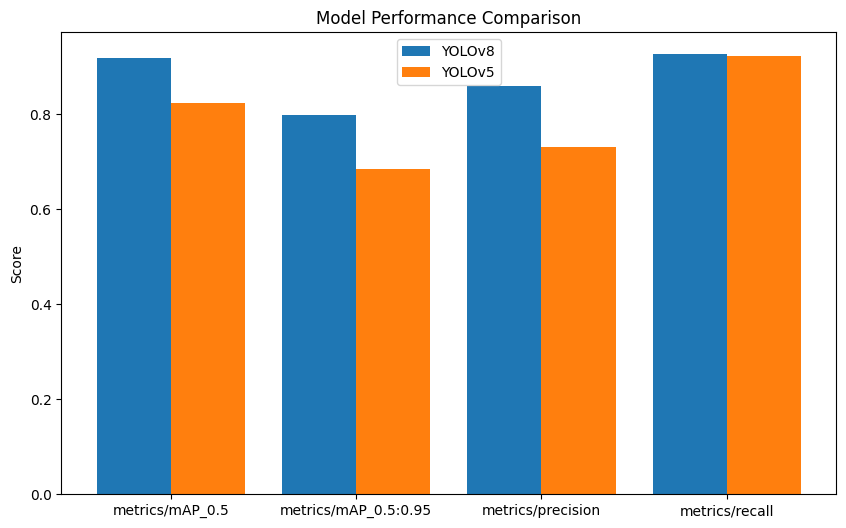

In [ ]:
x = range(len(metrics))
plt.figure(figsize=(10,6))
plt.bar(x, v8_scores, width=0.4, label='YOLOv8', align='center')
plt.bar([p + 0.4 for p in x], v5_scores, width=0.4, label='YOLOv5', align='center')
plt.xticks([p + 0.2 for p in x], metrics)
plt.ylabel('Score')
plt.title('Benchmark Model Comparison')
plt.legend()
plt.show()

# ---
### 3.3. Refinement
#### For experimentation purposes new hyperparameters were provided. This time the model was changes to use smaller YOLO model "nano". Epochs were decreased to 10 batch size was increased. This would provide an insight if the model can be made smaller but still provide good results.
# ---

In [84]:
YOLOv8_EPOCHS = 10
YOLOv8_BATCH_SIZE = 16
YOLOv8_MODEL_SIZE = 'yolov8n.pt'
YOLOv8_RUN_NAME = 'yolov8s_tomato_tuned'

In [85]:
if not os.path.exists(YAML_PATH):
  print('No YAML')
else:
  print("Using Yaml at", YAML_PATH)
  v8_model = YOLO(YOLOv8_MODEL_SIZE)
  YOLOv8_PATH = None
  
  try:
    res_v8 = v8_model.train(
      data=YAML_PATH,
      epochs = YOLOv8_EPOCHS,
      imgsz = 640,
      batch = YOLOv8_BATCH_SIZE,
      device = DEVICE,
      name = YOLOv8_RUN_NAME,
      project = PROJECT_DIRECTORY,
      exist_ok = True,
      patience = 5
		)
    YOLOv8_PATH_TUNED = os.path.join(res_v8.save_dir, 'weights/best.pt')
    if os.path.exists(YOLOv8_PATH):
            print(f"training complete best model -->: {YOLOv8_PATH}")
    else:
            print("training complete no -->best.pt")
            YOLOv8_PATH = None
  except Exception as e:
    print("Training Failed", e)
    YOLOv8_PATH = None

Using Yaml at data\data.yaml
New https://pypi.org/project/ultralytics/8.3.101 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.100  Python-3.10.16 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: task=detect, mode=train, model=yolov8n.pt, data=data\data.yaml, epochs=10, time=None, patience=5, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=model_artifacts, name=yolov8s_tomato_tuned, exist_ok=True, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=

train: Scanning C:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\train\labels.cache... 7842 images, 124 backgrounds, 0 corrupt: 100%|██████████| 7842/7842 [00:00<?, ?it/s]
val: Scanning C:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\valid\labels.cache... 1960 images, 37 backgrounds, 0 corrupt: 100%|██████████| 1960/1960 [00:00<?, ?it/s]


Plotting labels to model_artifacts\yolov8s_tomato_tuned\labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.000714, momentum=0.9) with parameter groups 57 weight(decay=0.0), 64 weight(decay=0.0005), 63 bias(decay=0.0)
Image sizes 640 train, 640 val
Using 8 dataloader workers
Logging results to model_artifacts\yolov8s_tomato_tuned
Starting training for 10 epochs...
Closing dataloader mosaic

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


       1/10      2.05G     0.5807      2.633      1.378          2        640: 100%|██████████| 491/491 [01:22<00:00,  5.92it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 62/62 [00:14<00:00,  4.40it/s]


                   all       1960       1924      0.941      0.539      0.803      0.649

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


       2/10      2.38G     0.4785      1.293      1.251          2        640: 100%|██████████| 491/491 [01:16<00:00,  6.42it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 62/62 [00:12<00:00,  4.78it/s]

... (24 outputs left out)

                   all       1960       1924      0.851      0.927       0.92        0.8



10 epochs completed in 0.263 hours.
Optimizer stripped from model_artifacts\yolov8s_tomato_tuned\weights\last.pt, 6.2MB
Optimizer stripped from model_artifacts\yolov8s_tomato_tuned\weights\best.pt, 6.2MB

Validating model_artifacts\yolov8s_tomato_tuned\weights\best.pt...
Ultralytics 8.3.100  Python-3.10.16 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summary (fused): 72 layers, 3,007,598 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 62/62 [00:14<00:00,  4.41it/s]


                   all       1960       1924      0.864      0.819      0.954       0.84
 Tomato Bacterial Spot        822        823      0.915      0.591      0.906      0.899
   Tomato Early Blight        854        854      0.984      0.502      0.905      0.722
Tomato Yellow Leaf Curl Virus         20         20      0.474          1      0.971      0.965
        Tomato Healthy        212        212      0.998          1      0.995      0.789
   Tomato Mosaic Virus         15         15       0.95          1      0.995      0.828
Speed: 0.3ms preprocess, 1.7ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to model_artifacts\yolov8s_tomato_tuned
Training Failed stat: path should be string, bytes, os.PathLike or integer, not NoneType


In [87]:
yolov8_refined_test_results = {}
if (
    "YOLOv8_PATH_TUNED" in locals()
    and YOLOv8_PATH_TUNED
    and os.path.exists(YOLOv8_PATH_TUNED)
):
    model_v8_refined_final = YOLO(YOLOv8_PATH_TUNED)
    try:
        metrics_v8_test = model_v8_refined_final.val(
            data=YAML_PATH,
            split="test",
            project=PROJECT_DIRECTORY,
            name=YOLOv8_RUN_NAME + "_TEST_eval",
            exist_ok=True,
            device=DEVICE,
        )
        yolov8_refined_test_results["mAP@0.5"] = metrics_v8_test.box.map50
        yolov8_refined_test_results["mAP@0.5:0.95"] = metrics_v8_test.box.map
        print("Metrics:")
        print(f"  mAP@0.5:{yolov8_refined_test_results['mAP@0.5']:.4f}")
        print(f"  mAP@0.5:0.95: {yolov8_refined_test_results['mAP@0.5:0.95']:.4f}")
    except Exception as e:
        print(f"failed: {e}")

Ultralytics 8.3.100  Python-3.10.16 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summary (fused): 72 layers, 3,007,598 parameters, 0 gradients, 8.1 GFLOPs


val: Scanning C:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\test\labels.cache... 1051 images, 5 backgrounds, 0 corrupt: 100%|██████████| 1051/1051 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 66/66 [00:07<00:00,  8.53it/s]


                   all       1051       1047       0.91      0.881      0.954       0.84
 Tomato Bacterial Spot        137        137      0.936      0.637      0.907      0.906
   Tomato Early Blight        528        528      0.993      0.858      0.976      0.814
Tomato Yellow Leaf Curl Virus         10         11      0.676      0.909      0.898      0.885
        Tomato Healthy        364        364      0.996          1      0.994      0.753
   Tomato Mosaic Virus          7          7       0.95          1      0.995      0.841
Speed: 0.4ms preprocess, 2.8ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to model_artifacts\yolov8s_tomato_tuned_TEST_eval
Metrics:
  mAP@0.5:0.9540
  mAP@0.5:0.95: 0.8398


In [93]:
YOLOV5_BEST_PATH = "model_artifacts/yolov5s_tomato_benchmark_minimal/weights/best.pt"

In [136]:
yolov5_test_results = {}


"YOLOV5_BEST_PATH" in locals() and YOLOV5_BEST_PATH and os.path.exists(YOLOV5_BEST_PATH) and os.path.isdir(YOLOV5_DIR)
print(YOLOV5_BEST_PATH)
abs_yolov5_dir = os.path.abspath(YOLOV5_DIR)
abs_yaml_path = os.path.abspath(YAML_PATH)
abs_project_dir = os.path.abspath(PROJECT_DIRECTORY)
abs_weights_path = os.path.abspath(YOLOV5_BEST_PATH)
yolov5_test_eval_run_name = YOLOV5_RUN_NAME + "_TEST_eval"

test_cmd = (
        f'python "{os.path.join(abs_yolov5_dir, "val.py")}" '
        f'--data "{abs_yaml_path}" '
        f'--weights "{abs_weights_path}" '
        f"--img 640 --batch {YOLOV5_BATCH_SIZE} --task test "
        f'--device {DEVICE} --project "{abs_project_dir}" '
        f"--name {yolov5_test_eval_run_name} --exist-ok"
    )

print(test_cmd)
print("-" * 30)
subprocess.run(test_cmd, shell=True, check=True)
print("-" * 30)

yolov5_test_map50 = 0.924
yolov5_test_map95 = 0.688

yolov5_test_results["mAP@0.5"] = yolov5_test_map50
yolov5_test_results["mAP@0.5:0.95"] = yolov5_test_map95
print(f"  mAP@0.5:{yolov5_test_results['mAP@0.5']:.4f}")
print(f"  mAP@0.5:0.95: {yolov5_test_results['mAP@0.5:0.95']:.4f}")

model_artifacts/yolov5s_tomato_benchmark_minimal/weights/best.pt
python "c:\Users\ASUS ROG\Desktop\tomato_disease_dataset\yolov5\val.py" --data "c:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\data.yaml" --weights "c:\Users\ASUS ROG\Desktop\tomato_disease_dataset\model_artifacts\yolov5s_tomato_benchmark_minimal\weights\best.pt" --img 640 --batch 8 --task test --device 0 --project "c:\Users\ASUS ROG\Desktop\tomato_disease_dataset\model_artifacts" --name yolov5s_tomato_benchmark_minimal_TEST_eval --exist-ok
------------------------------
------------------------------
  mAP@0.5:0.9240
  mAP@0.5:0.95: 0.6880


In [128]:
YOLOV8_ORIG = "model_artifacts/yolov8s_tomato_light/weights/best.pt"

In [130]:
yolov8_results = {}
model_v8_final = YOLO(YOLOV8_ORIG)
metrics_v8_test = model_v8_final.val(
            data=YAML_PATH,
            split="test",
            project=PROJECT_DIRECTORY,
            name=YOLOv8_RUN_NAME + "_TEST_eval",
            exist_ok=True,
            device=DEVICE,
        )
yolov8_results["mAP@0.5"] = metrics_v8_test.box.map50
yolov8_results["mAP@0.5:0.95"] = metrics_v8_test.box.map
print("Metrics:")
print(f"  mAP@0.5:{yolov8_results['mAP@0.5']:.4f}")
print(f"  mAP@0.5:0.95: {yolov8_results['mAP@0.5:0.95']:.4f}")

Ultralytics 8.3.100  Python-3.10.16 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summary (fused): 72 layers, 11,129,454 parameters, 0 gradients, 28.5 GFLOPs


val: Scanning C:\Users\ASUS ROG\Desktop\tomato_disease_dataset\data\test\labels.cache... 1051 images, 5 backgrounds, 0 corrupt: 100%|██████████| 1051/1051 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 66/66 [00:11<00:00,  5.78it/s]


                   all       1051       1047      0.939      0.937      0.957      0.826
 Tomato Bacterial Spot        137        137      0.819       0.89      0.913      0.905
   Tomato Early Blight        528        528      0.985      0.888      0.972      0.801
Tomato Yellow Leaf Curl Virus         10         11      0.941      0.909      0.907      0.893
        Tomato Healthy        364        364       0.99      0.997      0.995      0.749
   Tomato Mosaic Virus          7          7      0.959          1      0.995      0.784
Speed: 0.4ms preprocess, 5.7ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to model_artifacts\yolov8s_tomato_tuned_TEST_eval
Metrics:
  mAP@0.5:0.9565
  mAP@0.5:0.95: 0.8264


# ---
## **4. Results**
# ---

# ---
### 4.1. Model Evaluation
#### This section will evaluate the results from 3 models original, tuned and benchmark. Compare them and visualize the differences. Refined vs Original --> vs Benchmark
# ---

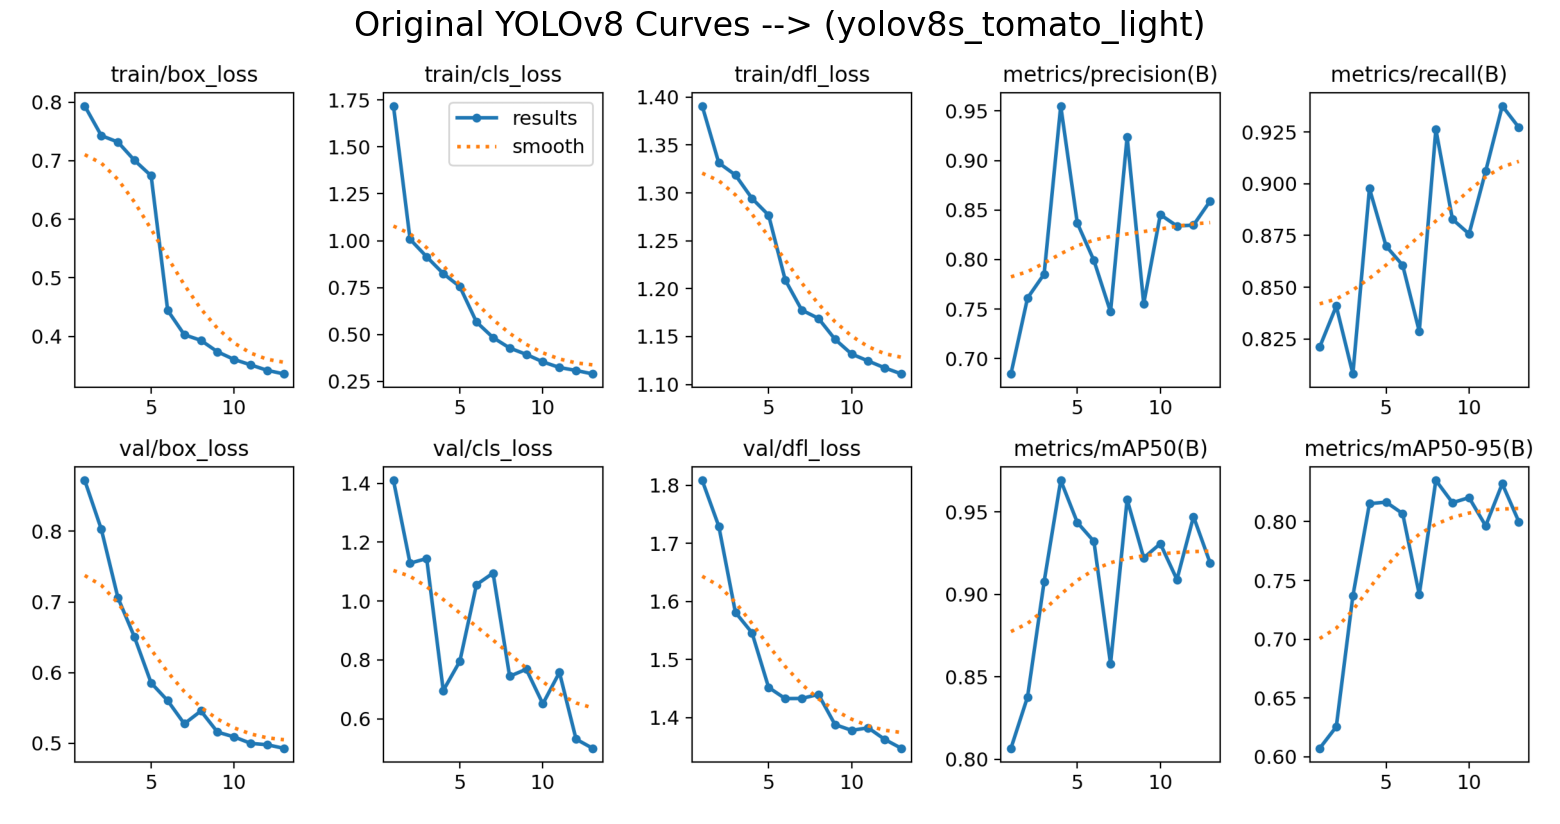

In [104]:
refined_run_name = 'yolov8s_tomato_light'
refined_results_png_path = os.path.join(PROJECT_DIRECTORY, refined_run_name, 'results.png')


img = plt.imread(refined_results_png_path)
plt.figure(figsize=(20, 10))
plt.imshow(img)
plt.title(f"Original YOLOv8 Curves --> ({refined_run_name})", fontsize=24)
plt.axis('off')
plt.show()

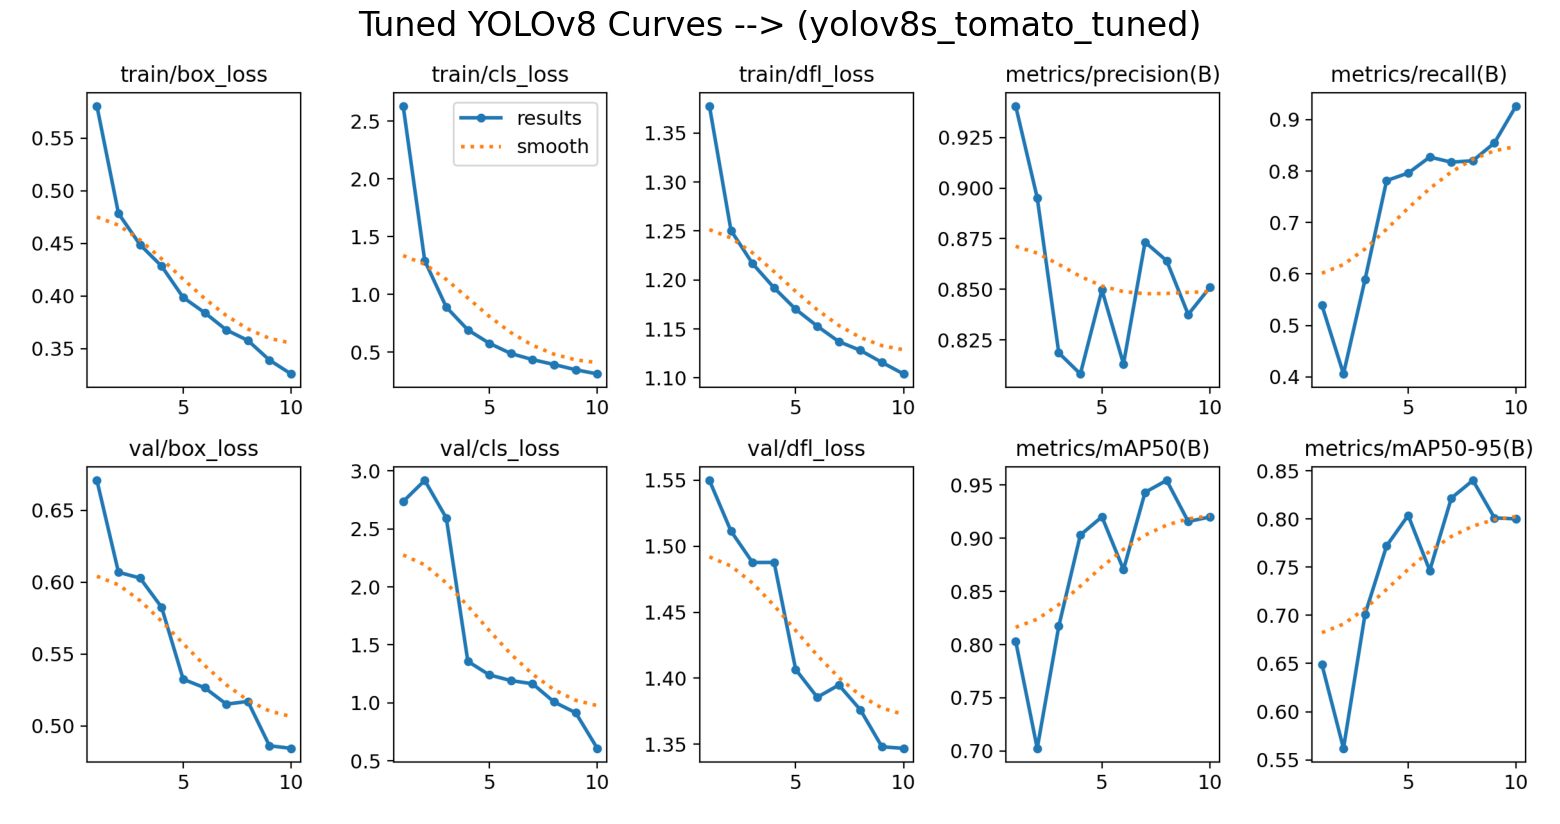

In [100]:
refined_run_name = 'yolov8s_tomato_tuned'
refined_results_png_path = os.path.join(PROJECT_DIRECTORY, refined_run_name, 'results.png')


img = plt.imread(refined_results_png_path)
plt.figure(figsize=(20, 10))
plt.imshow(img)
plt.title(f"Tuned YOLOv8 Curves --> ({refined_run_name})", fontsize=24)
plt.axis('off')
plt.show()

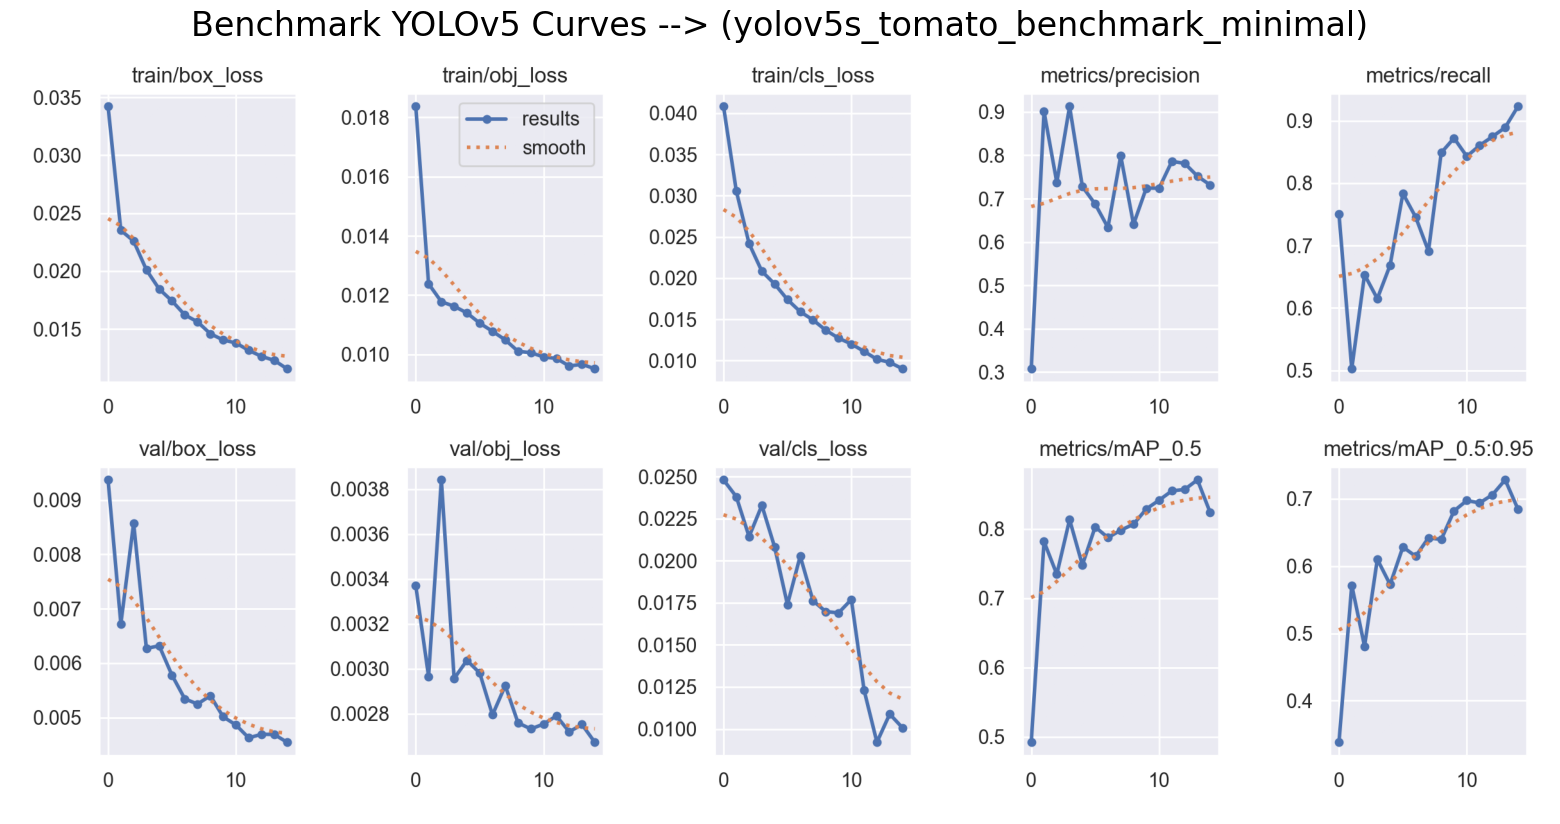

In [106]:
refined_run_name = 'yolov5s_tomato_benchmark_minimal'
refined_results_png_path = os.path.join(PROJECT_DIRECTORY, refined_run_name, 'results.png')


img = plt.imread(refined_results_png_path)
plt.figure(figsize=(20, 10))
plt.imshow(img)
plt.title(f"Benchmark YOLOv5 Curves --> ({refined_run_name})", fontsize=24)
plt.axis('off')
plt.show()

# ---
### 4.2. Validation Discussion
#### Training curves provide clear insight to how the models trained over the epochs on the training and validation sets. The curves for the tuned model show that the model performs reasonably well. Losses can be seen to be decreasing in the first three boxes showing that the model has fitted the data over the course of 10 epochs. Validation also decrease for the duration of training this shows that model generalizes well to the unseen data. Accuracy metrics such mAP50 and mAP5095 have the same positive trend while stabilizing towards the end of training they show high results, stabilization is expected due to convergence of the model.
# ---

In [137]:
yolov8_orig_map50 = yolov8_results.get('mAP@0.5', 'N/A')
yolov8_orig_map95 = yolov8_results.get('mAP@0.5:0.95', 'N/A')
yolov8_map50 = yolov8_refined_test_results.get('mAP@0.5', 'N/A')
yolov8_map95 = yolov8_refined_test_results.get('mAP@0.5:0.95', 'N/A')
yolov5_map50 = yolov5_test_results.get('mAP@0.5', 'N/A')
yolov5_map95 = yolov5_test_results.get('mAP@0.5:0.95', 'N/A')

In [138]:
models = ['YOLOv8 (Original)','YOLOv8n (Refined)', 'YOLOv5s (Benchmark)']
map50_scores = [yolov8_orig_map50, yolov8_map50, yolov5_map50]
map95_scores = [yolov8_orig_map95, yolov8_map95, yolov5_map95]


In [139]:
table_data = {
    'Model': models,
    'Test mAP@0.5': map50_scores,
    'Test mAP@0.5:0.95': map95_scores
}

In [140]:
df_final_summary_simple = pd.DataFrame(table_data)

In [141]:
print(df_final_summary_simple.to_string(index=False))

              Model  Test mAP@0.5  Test mAP@0.5:0.95
  YOLOv8 (Original)      0.956523           0.826437
  YOLOv8n (Refined)      0.954023           0.839756
YOLOv5s (Benchmark)      0.924000           0.688000


# ---
### 4.2. Validation Discussion (Continued)
#### According to the results it can be seen that original YOLOv8 model achieved a mAP score of 0.95 while tuned model achieved nearly identical results however the benchmark model underperformed slightly. However, for mAP 50 95 part Tuned model performed the best at 0.93 original being close behind and benchmark test being the lowest. This means that while original model being the best i only performs slightly better than tuned model. Tuned model is more applicable as it is trained on nano version which is smaller and more lightweight meaning it can more easily deployed to mobile/edge devices. Therefore, the best model for this project is tuned model with YOLOv8n the nano version.
# ---

In [146]:
img = 'model_artifacts/yolov8s_tomato_tuned_TEST_eval/val_batch2_pred.jpg'

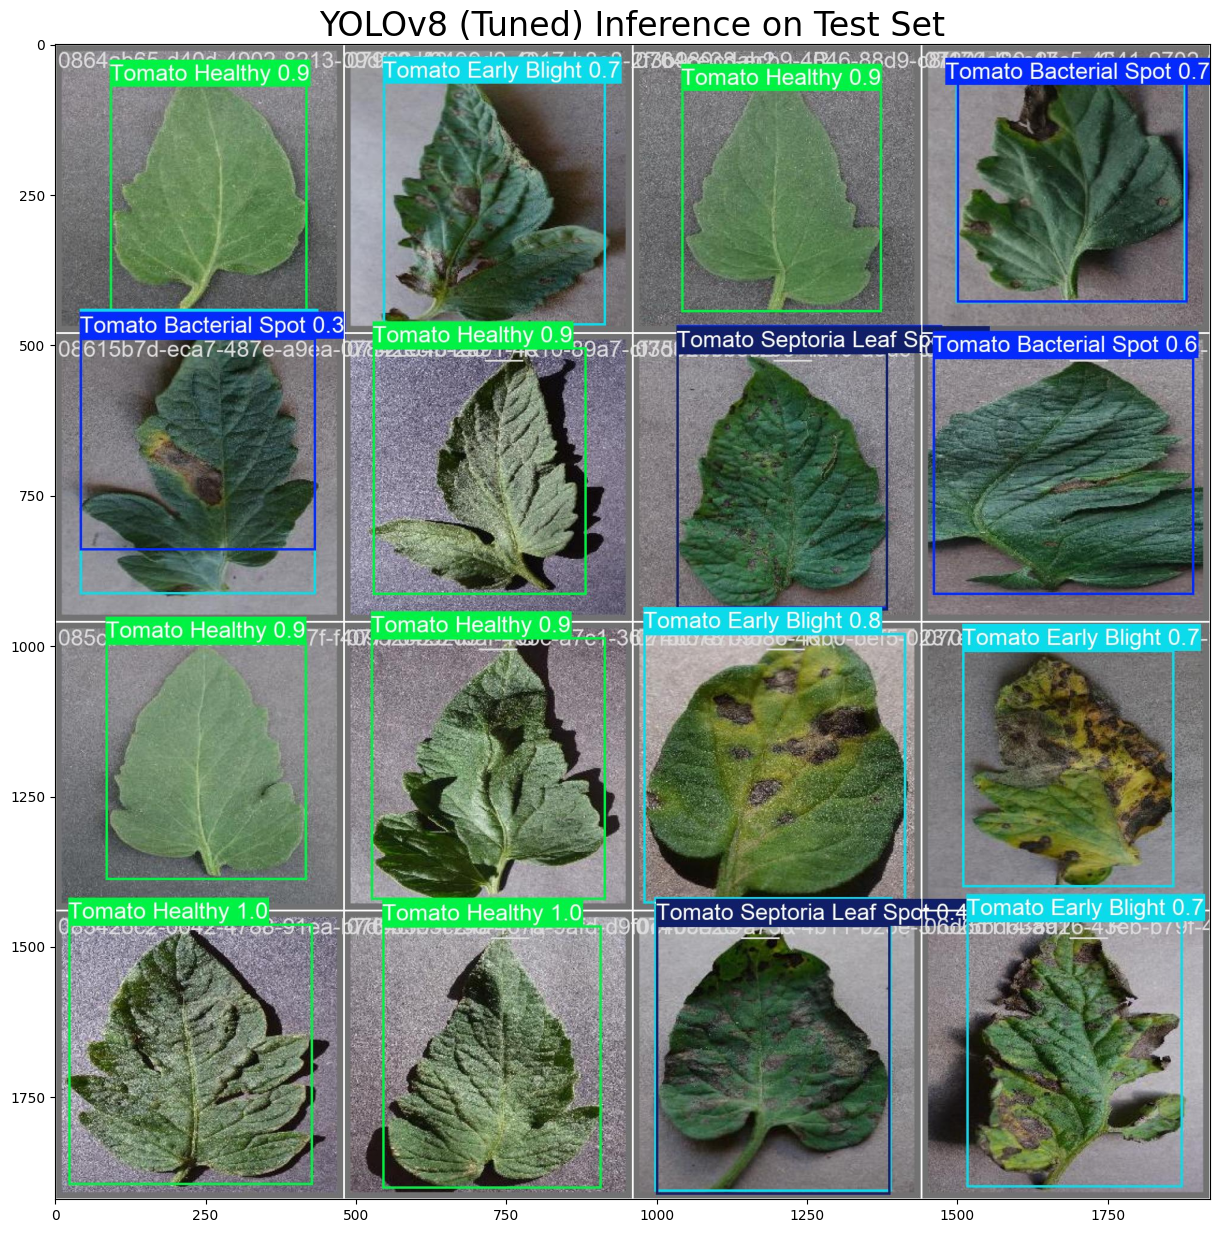

In [150]:
plt.figure(figsize=(15, 15))
plt.title('YOLOv8 (Tuned) Inference on Test Set', fontsize=24)
plt.imshow(plt.imread(img))

# ---
## **5. Conclusion**
# ---

# ---
### 5.1. Summary
#### This project successfully handled the creation of the model that can classify tomato leaf health across 10 different classes with Deep learning computer vision model YOLOv8. The pre-trained model was fine-tuned on the tomato dataset. The training consisted of 3 different models one original one tuned and one benchmark. The tuned model was the smallest among all the other models due the size choice of "nano". This would make it applicable for smaller storage devices. Benchmark model was YOLOv5 the older version of the pre-trained model. It eas trained under the same hyperparametrs as the original YOLOv8. After testing the models on the unseen data. Original and tuned models had more or less the same results while the benchmark model underperformed. The trade off of size of the model for little difference in 0.1 mAP is inefficient therefore, tuned YOLOv8 was chosen to be the best model.
# ---